# **Procesamiento de Lenguaje Natural**

## Maestría en Inteligencia Artificial Aplicada
#### Tecnológico de Monterrey
#### Prof. Luis Eduardo Falcón Morales

### **Actividad en Equipos: Sistema LLM + RAG con información tabular**

## Equipo 10
Team activity for the NLP course. Notebook version by Luis Velasco.


---
## 1: Instalación de librerías

In [ ]:
# Install all required libraries (modern LangChain standalone packages)

!pip install -q pdfplumber pymupdf \
    langchain langchain-core \
    langchain-text-splitters \
    langchain-chroma \
    langchain-huggingface \
    langchain-google-genai \
    langchain-groq \
    chromadb sentence-transformers \
    gradio google-generativeai

# Pin Pillow to exact version that satisfies both:
#   pdfplumber >= 12.2.0  AND  torchvision (avoids PIL._typing._Ink crash)
!pip install -q "Pillow==12.2.0" --force-reinstall

---
## 2: Importaciones

In [ ]:
import os           # set environment variables (API key)
import shutil       # delete folders (used to reset ChromaDB)
import pdfplumber   # table extraction from PDFs
import fitz         # PyMuPDF — fast plain text extraction
from pathlib import Path  # cross-platform file path handling

# ── Text Splitter ───────────────────────────────────────────────────
from langchain_text_splitters import RecursiveCharacterTextSplitter

# ── Core Data Structures ────────────────────────────────────────────
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

# ── Vector Store & Embeddings ───────────────────────────────────────
import chromadb                                      # ChromaDB client (used for cache reset)
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

# ── LLM ─────────────────────────────────────────────────────────────
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from langchain_groq import ChatGroq

# ── Chat Interface ──────────────────────────────────────────────────
import gradio as gr

print('All imports successful')

All imports successful


---
## 3: Configuración del API Keys


In [ ]:
from google.colab import userdata

# ── API Keys ────────────────────────────────────────────────────────
GOOGLE_API_KEY = userdata.get('GEMINI_KEY')
os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY

HF_TOKEN = userdata.get('HF_TOKEN')
os.environ["HUGGINGFACEHUB_API_TOKEN"] = HF_TOKEN

GROQ_API_KEY = userdata.get('API_KEY_GROQ')

# ── Verify both loaded ───────────────────────────────────────────────
assert GOOGLE_API_KEY, "GEMINI_KEY not found in Colab Secrets"
assert HF_TOKEN,       "HF_TOKEN not found in Colab Secrets"
assert GROQ_API_KEY,   "API_KEY_GROQ not found in Colab Secrets"

print('API Keys set!')

print(f"Google key loaded: ...{GOOGLE_API_KEY[-4:]}")
print(f"HF token loaded:   ...{HF_TOKEN[-4:]}")
print(f"Groq key loaded:   ...{GROQ_API_KEY[-4:]}")

API Keys set!
Google key loaded: ...pVaw
HF token loaded:   ...VoPx
Groq key loaded:   ...vfgc


---
## 4: Carga de archivos PDF

Sube los archivos `python_cheatsheet.pdf` y `ml_cheatsheet.pdf` usando el panel de archivos de Colab (ícono de carpeta).

In [ ]:
# If running in Colab, use the file upload widget
from google.colab import files

print('Uploading files...')
uploaded = files.upload()  # Select python_cheatsheet.pdf and ml_cheatsheet.pdf

PDF_PATHS = {
    'python': 'python_cheatsheet.pdf',
    'ml': 'ml_cheatsheet.pdf'
}

print(f'\n Files uploaded: {list(uploaded.keys())}')

Uploading files...


Saving ml_cheatsheet.pdf to ml_cheatsheet.pdf
Saving python_cheatsheet.pdf to python_cheatsheet.pdf

 Files uploaded: ['ml_cheatsheet.pdf', 'python_cheatsheet.pdf']


---
## Sección 5: Extracción de texto y tablas de los PDFs

**Estrategia adaptativa por tipo de PDF:**

- **Python Cheatsheet** (layout multi-columna, 4 columnas por página):
  - `PyMuPDF` (`get_text("blocks")`) → divide la página en bloques de texto individuales
  - Ordenamiento por columna: se asigna cada bloque a su columna por posición `x`, luego se ordena de arriba a abajo dentro de cada columna
  - `pdfplumber` **descartado** para este PDF: todas sus "tablas" detectadas son en realidad grillas de layout visual (hasta 96 columnas), no tablas de datos reales

- **ML Cheatsheet** (tabla de datos estructurada, 5 columnas):
  - `pdfplumber` → extrae las tablas reales de algoritmos (descripción, casos de uso, ventajas, desventajas)
  - `PyMuPDF` → extrae los nombres de los algoritmos (bloques separados fuera de la tabla)
  - Combinados en entradas estructuradas con etiquetas Markdown: `**Description**`, `**Use Cases**`, etc.

**Filtro `is_real_table()`**: Rechaza grillas de layout (>8 columnas) y acepta solo tablas de datos reales (≤8 columnas).

**Reto clave encontrado**: Las tablas detectadas por `pdfplumber` en PDFs de layout visual no son tablas de datos — son la página completa convertida en una grilla. Esto generaba contenido mezclado e ilegible, la principal fuente de alucinaciones del modelo al responder preguntas tabulares.

In [ ]:
# ══════════════════════════════════════════════════════════════════
# SECTION 5: PDF EXTRACTION
# Two separate strategies:
#   - Python cheatsheet: PyMuPDF blocks only (column-ordered text)
#                        pdfplumber tables SKIPPED (all are fake grids)

#   - ML cheatsheet:     pdfplumber tables (real 5-col data tables)
#                        + PyMuPDF blocks for headers/labels
# ══════════════════════════════════════════════════════════════════

def get_column_sorted_text(pymupdf_page):
    """
    Reads a multi-column PDF page in correct order:
    all of column 1 top→bottom, then column 2, etc.
    Auto-detects column count from page width.
    """
    page_width = pymupdf_page.rect.width
    blocks = pymupdf_page.get_text("blocks", sort=False)
    text_blocks = [b for b in blocks if b[6] == 0 and b[4].strip()]

    # Auto-detect columns: page_width / 250 works for both PDFs
    num_cols = max(1, round(page_width / 250))
    col_width = page_width / num_cols

    def col_index(b):
        return int(b[0] / col_width)

    sorted_blocks = sorted(text_blocks, key=lambda b: (col_index(b), b[1]))
    return "\n\n".join(b[4].strip() for b in sorted_blocks)

In [ ]:
def extract_ml_tables(pdf_path):
    """
    Dedicated extractor for the ML cheatsheet.
    Reads the 5-column tables (description, use cases, advantages,
    disadvantages) and combines them with algorithm names from
    PyMuPDF blocks. Returns structured text per algorithm.
    """
    # Column meaning in the ML table (col 0 is always NULL/empty)
    COL_HEADERS = ["", "Description", "Use Cases", "Advantages", "Disadvantages"]

    content_parts = []

    # Get algorithm names from PyMuPDF (they appear as separate blocks)
    doc = fitz.open(pdf_path)
    page = doc[0]
    all_blocks = page.get_text("blocks", sort=True)
    # Algorithm names are short blocks in the left-center area (x 400-650)
    algo_names = [
        b[4].strip() for b in all_blocks
        if b[6] == 0
        and 400 < b[0] < 650          # x position of algorithm name column
        and len(b[4].strip()) < 40    # short text = name, not description
        and b[4].strip()
    ]
    doc.close()

    # Get table content from pdfplumber
    with pdfplumber.open(pdf_path) as pdf:
        page = pdf.pages[0]
        tables = page.extract_tables()

        # Filter real 5-column tables (skip the 1-col header table)
        real_tables = [t for t in tables if max(len(r) for r in t) == 5]

        # Pair each table row with an algorithm name
        algo_idx = 0
        for table in real_tables:
            for row in table:
                # Skip empty/null rows
                if not any(c and str(c).strip() for c in row):
                    continue

                # Get algorithm name for this row
                algo_name = algo_names[algo_idx] if algo_idx < len(algo_names) else "Unknown"
                algo_idx += 1

                # Build structured text block for this algorithm
                entry_parts = [f"\n## {algo_name}"]
                for col_i, header in enumerate(COL_HEADERS):
                    if col_i == 0 or not header:
                        continue  # skip the empty first column
                    cell_text = str(row[col_i]).strip() if row[col_i] else ""
                    if cell_text and cell_text != "NULL":
                        # Clean up the cell text
                        cell_text = cell_text.replace("use cases\n", "").strip()
                        entry_parts.append(f"**{header}**: {cell_text}")

                content_parts.append("\n".join(entry_parts))

    return "\n\n".join(content_parts)

In [ ]:

def extract_pdf(pdf_path, label):
    """
    Main extractor — uses different strategies per PDF type:
      - Python cheatsheet: PyMuPDF column-ordered blocks only
      - ML cheatsheet: dedicated table extractor + PyMuPDF blocks
    Returns a list of LangChain Document objects (one per page).
    """
    documents = []
    doc_pymupdf = fitz.open(pdf_path)

    with pdfplumber.open(pdf_path) as pdf:
        for page_num, page in enumerate(pdf.pages):
            page_content_parts = []

            # ── ML CHEATSHEET: use dedicated table extractor ─────────
            if label == 'ML Cheatsheet' and page_num == 0:
                ml_text = extract_ml_tables(pdf_path)
                if ml_text:
                    page_content_parts.append(ml_text)

            # ── PYTHON CHEATSHEET: column-ordered text only ──────────
            # pdfplumber tables are ALL fake layout grids for this PDF
            # so we skip them entirely and rely only on PyMuPDF blocks
            pymupdf_page = doc_pymupdf[page_num]
            plain_text = get_column_sorted_text(pymupdf_page)
            if plain_text:
                page_content_parts.append(plain_text)

            # ── WRAP INTO LANGCHAIN DOCUMENT ─────────────────────────
            full_page_text = "\n".join(page_content_parts).strip()
            if full_page_text:
                documents.append(Document(
                    page_content=full_page_text,
                    metadata={
                        "source": label,
                        "page":   page_num + 1,
                        "file":   pdf_path
                    }
                ))

    doc_pymupdf.close()
    print(f'--> [{label}] Extracted {len(documents)} pages')
    return documents


print('All extraction functions defined')

All extraction functions defined


In [ ]:
# ── RUN EXTRACTION ───────────────────────────────────────────────────
python_docs = extract_pdf(PDF_PATHS['python'], label='Python Cheatsheet')
ml_docs     = extract_pdf(PDF_PATHS['ml'],     label='ML Cheatsheet')

all_docs = python_docs + ml_docs
print(f'\n Total pages extracted: {len(all_docs)}')

# ── VERIFY ALL PAGES ─────────────────────────────────────────────────
for i, doc in enumerate(all_docs):
    print(f"\n{'='*60}")
    print(f" Doc {i+1} | {doc.metadata['source']} | Page {doc.metadata['page']}")
    print(f"   Length: {len(doc.page_content)} chars")
    print(doc.page_content[:500])

--> [Python Cheatsheet] Extracted 3 pages
--> [ML Cheatsheet] Extracted 1 pages

 Total pages extracted: 4

 Doc 1 | Python Cheatsheet | Page 1
   Length: 4943 chars
Real Python
Pocket Reference

Visit realpython.com to
turbocharge your
Python learning with
in‑depth tutorials,
real‑world examples,
and expert guidance.

Getting Started

Follow these guides to kickstart your Python journey:

realpython.com/what-can-i-do-with-python
realpython.com/installing-python
realpython.com/python-first-steps

Start the Interactive Shell

$ python

Quit the Interactive Shell

>>> exit()

Run a Script

$ python my_script.py

Run a Script in Interactive Mode

$ python -i my

 Doc 2 | Python Cheatsheet | Page 2
   Length: 5373 chars
Loops

range(5) generates 0 through 4
Use enumerate() to get index and value
break exits the loop, continue skips to next
Be careful with while to not create an infinite loop

For Loops

# Loop through range
for i in range(5):      # 0, 1, 2, 3, 4
    print(i)

# Loop throu

---
## 6: Chunking (División de texto)

Se divide el contenido extraído en chunks de **800 caracteres** con un
solapamiento de **150 caracteres** entre chunks consecutivos.

- `chunk_size=800` → cada chunk representa un tema específico (~200 tokens),
  lo que mejora la precisión de los embeddings vectoriales
- `chunk_overlap=150` → evita perder contexto cuando una respuesta cae
  exactamente en el límite entre dos chunks
- `separators` priorizados → se corta preferentemente entre párrafos (`\n\n`),
  y nunca en medio de una tabla Markdown (`[/TABLE]` como separador explícito)

In [ ]:
# ── CONFIGURE THE TEXT SPLITTER ─────────────────────────────────────

splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,     # Max characters per chunk (~200 tokens)
                        # Large enough to contain one full topic section
                        # Small enough to represent a single concept in the embedding

    chunk_overlap=150,  # Last 150 chars of each chunk repeat at the start of the next
                        # Prevents losing context when an answer falls on a chunk boundary

    separators=[        # Cut preference order — tries each one until chunk fits:
        "\n\n",         # 1st choice: double newline = section/paragraph break (ideal)
        "\n",           # 2nd choice: single newline = line break
        "[/TABLE]",     # 3rd choice: end of a Markdown table — never cut mid-table
        ".",            # 4th choice: end of sentence
        " ",            # 5th choice: word boundary (last resort)
        ""              # 6th choice: individual character (only if nothing else fits)
    ]
)

# ── SPLIT ALL DOCUMENTS INTO CHUNKS ─────────────────────────────────
# split_documents() preserves the metadata (source, page, file) from
# each Document object — every chunk knows which PDF and page it came from
chunks = splitter.split_documents(all_docs)

print(f'   Total chunks created: {len(chunks)}')
print(f'   Average chunk length: {sum(len(c.page_content) for c in chunks) // len(chunks)} chars')

# ── PREVIEW A SAMPLE CHUNK ───────────────────────────────────────────
# chunks[5] is a mid-page chunk — good for checking that content
# and metadata are preserved correctly after splitting

print('\n--- Sample chunk ---')
print(chunks[5].page_content)
print('Metadata:', chunks[5].metadata)

# Expected metadata: {'source': 'Python Cheatsheet', 'page': 1, 'file': '...'}

   Total chunks created: 44
   Average chunk length: 674 chars

--- Sample chunk ---
String Formatting

# f-strings
name = "Aubrey"
age = 2
f"Hello, {name}!"               # "Hello, Aubrey!"
f"{name} is {age} years old"    # "Aubrey is 2 years old"
f"Debug: {age=}"                # "Debug: age=2"

# Format method
template = "Hello, {name}! You're {age}."
template.format(name="Aubrey", age=2)    # "Hello, Aubrey! You're 2."

Raw Strings

# Normal string with an escaped tab
"This is:\tCool."       # "This is:    Cool."

# Raw string with escape sequences
r"This is:\tCool."      # "This is:\tCool."

Learn More on realpython.com/search:

strings ∙ string methods ∙ slice notation ∙ raw strings

Numbers & Math

Arithmetic Operators

10 + 3    # 13
10 - 3    # 7
10 * 3    # 30
10 / 3    # 3.3333333333333335
10 // 3   # 3
10 % 3    # 1
2 ** 3    # 8

Useful Functions
Metadata: {'source': 'Python Cheatsheet', 'page': 1, 'file': 'python_cheatsheet.pdf'}


In [ ]:
# Search for the chunk containing ZeroDivisionError
# This verifies question (a) from the activity is answerable
keyword = "ZeroDivisionError"
found = [(i, c) for i, c in enumerate(chunks) if keyword in c.page_content]

print(f'Chunks containing "{keyword}": {len(found)}')
for i, chunk in found:
    print(f'\n--- Chunk {i} | {chunk.metadata["source"]} p.{chunk.metadata["page"]} ---')
    print(chunk.page_content)

Chunks containing "ZeroDivisionError": 1

--- Chunk 13 | Python Cheatsheet p.2 ---
def speak(self):
       return f"{self.name} barks!"

Learn More on realpython.com/search:

object oriented programming ∙ classes

Exceptions

When Python runs and encounters an error, it creates an exception
Use specific exception types when possible
else runs if no exception occurred
finally always runs, even after errors

Try-Except

try:

number = int(input("Enter a number: "))
   result = 10 / number
except ValueError:

print("That's not a valid number!")
except ZeroDivisionError:

print("Cannot divide by zero!")
else:

print(f"Result: {result}")
finally:

print("Calculation attempted")

Common Exceptions


---
## 7: Base vectorial con ChromaDB

Se generan embeddings locales con `sentence-transformers` y se almacenan en ChromaDB.

- **`all-MiniLM-L6-v2`** :  modelo de embeddings ligero que corre localmente, sin API key ni costo. Convierte cada chunk en un vector de 384 dimensiones que representa su significado semántico

- **ChromaDB**: base de datos vectorial que almacena los 44 vectores y permite búsqueda por similitud coseno. Se persiste en disco (`./cheatsheet_vectordb`) para no recalcular los embeddings si la sesión de Colab se reinicia


In [ ]:
print(' Loading embedding model ......')

# Free local embeddings — no API key needed
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device": "cuda"}  # Change to 'cuda' if GPU is available
)

print('Embedding model loaded')

# Reset before rebuilding — prevents duplicate vectors on re-runs
shutil.rmtree("./cheatsheet_vectordb", ignore_errors=True)
try:
    chromadb.api.client.SharedSystemClient.clear_system_cache()
except Exception:
    pass

# Build ChromaDB vector store
print('Building ChromaDB vector store......')

import shutil
shutil.rmtree("./cheatsheet_vectordb", ignore_errors=True)  # always start fresh

# Chroma.from_documents():
#   1. Passes each chunk's text through the embedding model → 384-dim vector
#   2. Stores (vector + original text + metadata) together in ChromaDB
#   3. Persists the collection to disk so embeddings survive Colab session resets

vectorstore = Chroma.from_documents(
    documents=chunks,                        # 44 chunks with text + metadata
    embedding=embeddings,                    # embedding model defined above
    persist_directory="./cheatsheet_vectordb",  # saved to Colab disk
    collection_name="cheatsheets"            # name for this collection inside ChromaDB
)

print(f'Vector store created with {vectorstore._collection.count()} vectors')

 Loading embedding model ......


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded
Building ChromaDB vector store......
Vector store created with 44 vectors


---
## 8: Retriever + LLM + RAG Pipeline



Se conectan los componentes del pipeline en una cadena LangChain:

1. **Retriever**:   busca en ChromaDB los 4 chunks más similares semánticamente a la pregunta
2. **Prompt**:  estructura el contexto recuperado + la pregunta del usuario para Gemini
3. **Modelo LLM**:  genera la respuesta basándose únicamente en el contexto
4. **StrOutputParser**: convierte la respuesta del LLM a texto plano

El prompt incluye instrucción explícita de responder **solo con información del contexto**,
lo que reduce alucinaciones al impedir que el modelo use conocimiento externo.

In [ ]:
# ── RETRIEVER ────────────────────────────────────────────────────────
# Converts the question to a vector and finds the k most similar
# chunks in ChromaDB using cosine similarity
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 5}  # top 5 most semantically similar chunks
)

In [ ]:
# ── LLM Selector ────────────────────────────────────────────────────
# temperature=0.2 → mostly deterministic, slight flexibility for phrasing
# Lower = more factual; raise to 0.7+ for more creative/conversational answers

# Switch providers by setting PROVIDER to "gemini" or "groq"

PROVIDER = "groq"

# ── Gemini models (uncomment one) ───────────────────────────────────
#gemini_model_id = "gemini-2.0-flash-lite"
#gemini_model_id = "gemini-2.0-flash"
gemini_model_id = "gemini-2.5-flash"
#gemini_model_id = "gemini-3.5-flash"

# ── Groq models (uncomment one) ─────────────────────────────────────
groq_model_id = "llama-3.1-8b-instant"    # fast, 14,400 req/day free
#groq_model_id = "llama3-8b-8192"         # stable older variant
#groq_model_id = "gemma2-9b-it"           # Google Gemma via Groq

# ── Build the LLM ───────────────────────────────────────────────────
if PROVIDER == "gemini":
    llm = ChatGoogleGenerativeAI(
        model=gemini_model_id,
        temperature=0.2,
        google_api_key=GOOGLE_API_KEY
    )
    print(f"LLM ready: Gemini -> {gemini_model_id}")

elif PROVIDER == "groq":
    llm = ChatGroq(
        model=groq_model_id,
        temperature=0.2,
        api_key=GROQ_API_KEY
    )
    print(f"LLM ready: Groq -> {groq_model_id}")

LLM ready: Groq -> llama-3.1-8b-instant


In [ ]:
# ── PROMPT TEMPLATE ──────────────────────────────────────────────────
# Anti-hallucination design: Gemini must answer ONLY from retrieved context
# If the answer isn't in the chunks, it says so instead of guessing

RAG_PROMPT = """\
You are a helpful technical assistant. Answer the user's question \
STRICTLY based on the context below. \
If the answer is not in the context, say: "I could not find this information in the provided documents."

Context (extracted from Python and ML cheat-sheet documents):
{context}

Question: {question}

Answer (be concise and precise):
"""

prompt = ChatPromptTemplate.from_template(RAG_PROMPT)

In [ ]:
# ── FORMAT RETRIEVED CHUNKS ──────────────────────────────────────────

def format_docs(docs):
    # Joins the top-k chunks into one context string
    # Source labels help Gemini cite where each answer comes from
    return "\n\n".join(
        f"[Source: {d.metadata.get('source','?')}, Page {d.metadata.get('page','?')}]\n{d.page_content}"
        for d in docs
    )

In [ ]:

# ── RAG CHAIN (LangChain Expression Language) ────────────────────────
# Data flow:
#   question ──→ retriever finds top-5 chunks ──→ format_docs joins them
#            ──→ prompt fills {context}+{question} ──→ Gemini answers
#            ──→ StrOutputParser returns plain text string
rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)

print(' RAG pipeline ready!')



 RAG pipeline ready!


---
## 9: Preguntas requeridas por la actividad

Se validan las respuestas del chatbot con las 6 preguntas requeridas por la actividad.
Cada pregunta verifica que el retriever recupera el chunk correcto y que Gemini
genera una respuesta precisa basada únicamente en el contexto de los cheatsheets.

| Inciso | Fuente | Pregunta |
|---|---|---|
| a | Python p.2 | Excepción al dividir entre cero |
| b | Python p.1 | 2 ejemplos de string methods |
| c | ML p.1 | Desventajas de Random Forest |
| d | ML p.1 | 3 casos de uso de clustering |
| e | Python p.3 | Diferencia entre list y tuple |
| f | ML p.1 | Propósito de cross-validation |

In [ ]:
required_questions = [
    # (a) Python — Exceptions section
    "According to the Exceptions section, what exception is raised when dividing by zero?",
    # (b) Python — String methods
    "Can you provide 2 examples of string methods in Python?",
    # (c) ML — Random Forest disadvantages
    "What are the main disadvantages of using the Random Forest model?",
    # (d) ML — Unsupervised learning / clustering use cases
    "What are 3 use cases of clustering techniques in Unsupervised Learning?",
    # (e) Extra Python question
    "What is the difference between a list and a tuple in Python?",
    # (f) Extra ML question
    "What is the purpose of cross-validation in Machine Learning?",
]

import time

print('=' * 70)
for i, question in enumerate(required_questions, 1):
    print(f'\n Question {i}: {question}')
    #print('-' * 50)
    answer = rag_chain.invoke(question)
    print(f'---------> Answer: {answer}')
    print('=' * 70)
    time.sleep(5)


 Question 1: According to the Exceptions section, what exception is raised when dividing by zero?
---------> Answer: ZeroDivisionError

 Question 2: Can you provide 2 examples of string methods in Python?
---------> Answer: Here are 2 examples of string methods in Python:

1. `upper()`: "a".upper() returns "A"
2. `replace()`: "abc".replace("bc", "ha") returns "aha"

 Question 3: What are the main disadvantages of using the Random Forest model?
---------> Answer: The main disadvantages of using the Random Forest model are:

1. Training complexity can be high
2. Not very interpretable

 Question 4: What are 3 use cases of clustering techniques in Unsupervised Learning?
---------> Answer: Based on the provided documents, the 3 use cases of clustering techniques in Unsupervised Learning are:

1. Fraud detection
2. Document clustering based on similarity
3. Customer segmentation

 Question 5: What is the difference between a list and a tuple in Python?
---------> Answer: In Python, the mai

### Resultados de las preguntas requeridas

| # | Fuente | Pregunta | Respondida correctamente |
|---|--------|----------|--------------------------|
| a | Python p.2 | Excepción al dividir entre cero | Sí |
| b | Python p.1 | 2 ejemplos de string methods | Sí |
| c | ML p.1 | Desventajas de Random Forest | Sí |
| d | ML p.1 | 3 casos de uso de clustering | Sí |
| e | Python p.3 | Diferencia entre list y tuple | Sí |
| f | ML p.1 | Propósito de cross-validation | No — término ausente en los chunks |

---
## 10: Interfaz interactiva con Gradio


Se despliega el chatbot RAG con una interfaz web interactiva usando Gradio.
El sistema recupera los chunks más relevantes de ChromaDB y genera respuestas
basadas únicamente en el contenido de los cheatsheets.

- `chatbot_response()` invoca el pipeline RAG y añade las fuentes consultadas a cada respuesta
- `gr.ChatInterface` gestiona el historial de conversación y los ejemplos precargados
- `demo.launch(share=True)` genera un enlace público temporal desde Colab

In [ ]:
def chatbot_response(message, history):
    if not message.strip():
        return "Please enter a question."
    try:
        # retrieve() now uses .invoke() — get_relevant_documents() was removed in LangChain 0.2+
        retrieved_docs = retriever.invoke(message)
        sources = list(set(d.metadata.get("source", "?") for d in retrieved_docs))

        # Run the full RAG pipeline: retriever -> prompt -> LLM -> parser
        answer = rag_chain.invoke(message)

        # Append source footer so graders can verify grounding
        source_note = f"\n\n_Sources consulted: {', '.join(sources)}_"
        return answer + source_note
    except Exception as e:
        return f"Error: {str(e)}"

In [ ]:
# ── Dynamic model label for the Gradio header ───────────────────────
if PROVIDER == "gemini":
    model_label = f"Gemini ({gemini_model_id})"
elif PROVIDER == "groq":
    model_label = f"Groq ({groq_model_id})"
else:
    model_label = "LLM"


# ── Gradio Interface ─────────────────────────────────────────────────
with gr.Blocks(title="Chatbot Python & ML Cheatsheet RAG") as demo:   # theme moved to launch()
    gr.Markdown(f"""
# Chatbot Python & ML Cheatsheet
**RAG System — {model_label} + ChromaDB**

Ask questions about Python programming or Machine Learning based on the cheat-sheet documents.
""")
    gr.ChatInterface(
        fn=chatbot_response,
        examples=[
            "What exception is raised when dividing by zero in Python?",
            "Give me 2 examples of Python string methods",
            "What are the disadvantages of Random Forests?",
            "What are 3 use cases of clustering in Unsupervised Learning?",
        ],
        submit_btn="Ask",
    )

demo.launch(share=True, debug=False, theme=gr.themes.Soft())

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://23bdaa665dc85caa25.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Demostración del chatbot

Las siguientes capturas muestran el comportamiento del sistema RAG en distintos escenarios.

---

**1. Interfaz inicial — ejemplos precargados**

Vista inicial del chatbot con los 4 ejemplos precargados disponibles para el usuario.

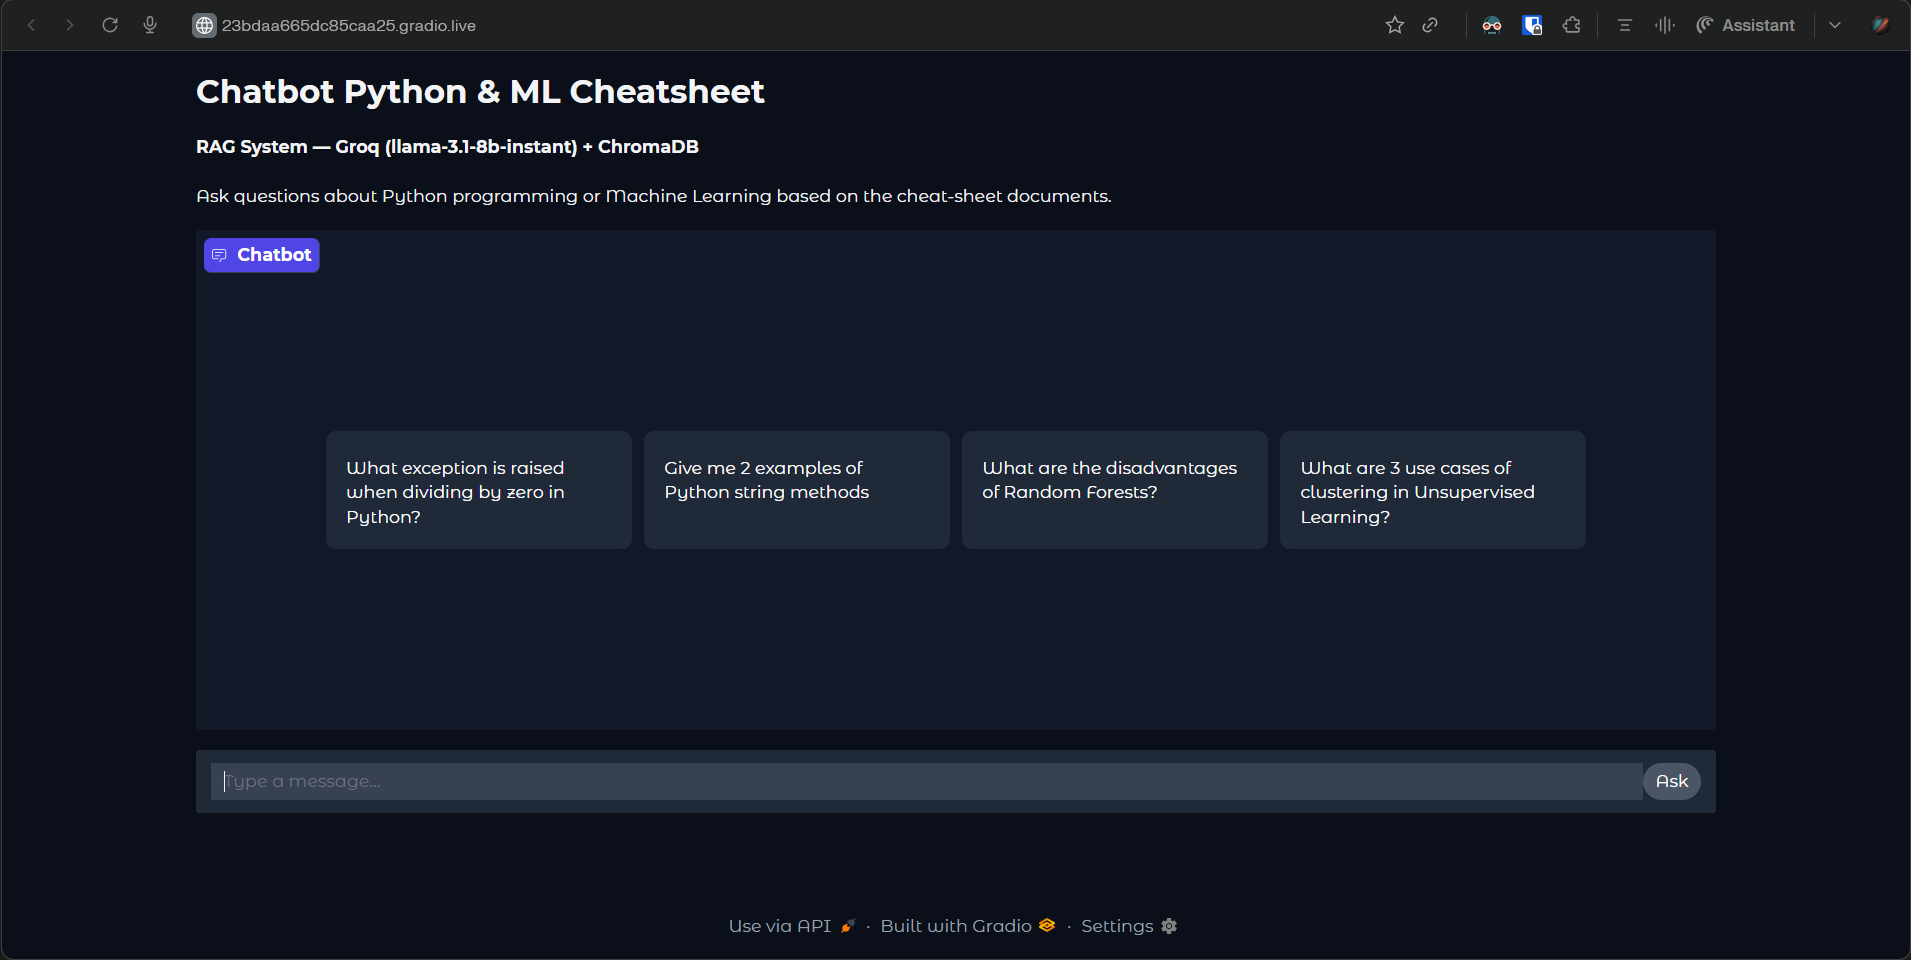

---

**2. Pregunta sobre métodos de cadena en Python**

El sistema recupera el chunk correcto del Python Cheatsheet y devuelve dos ejemplos con su sintaxis: `upper()` y `replace()`, tomados directamente del documento fuente.

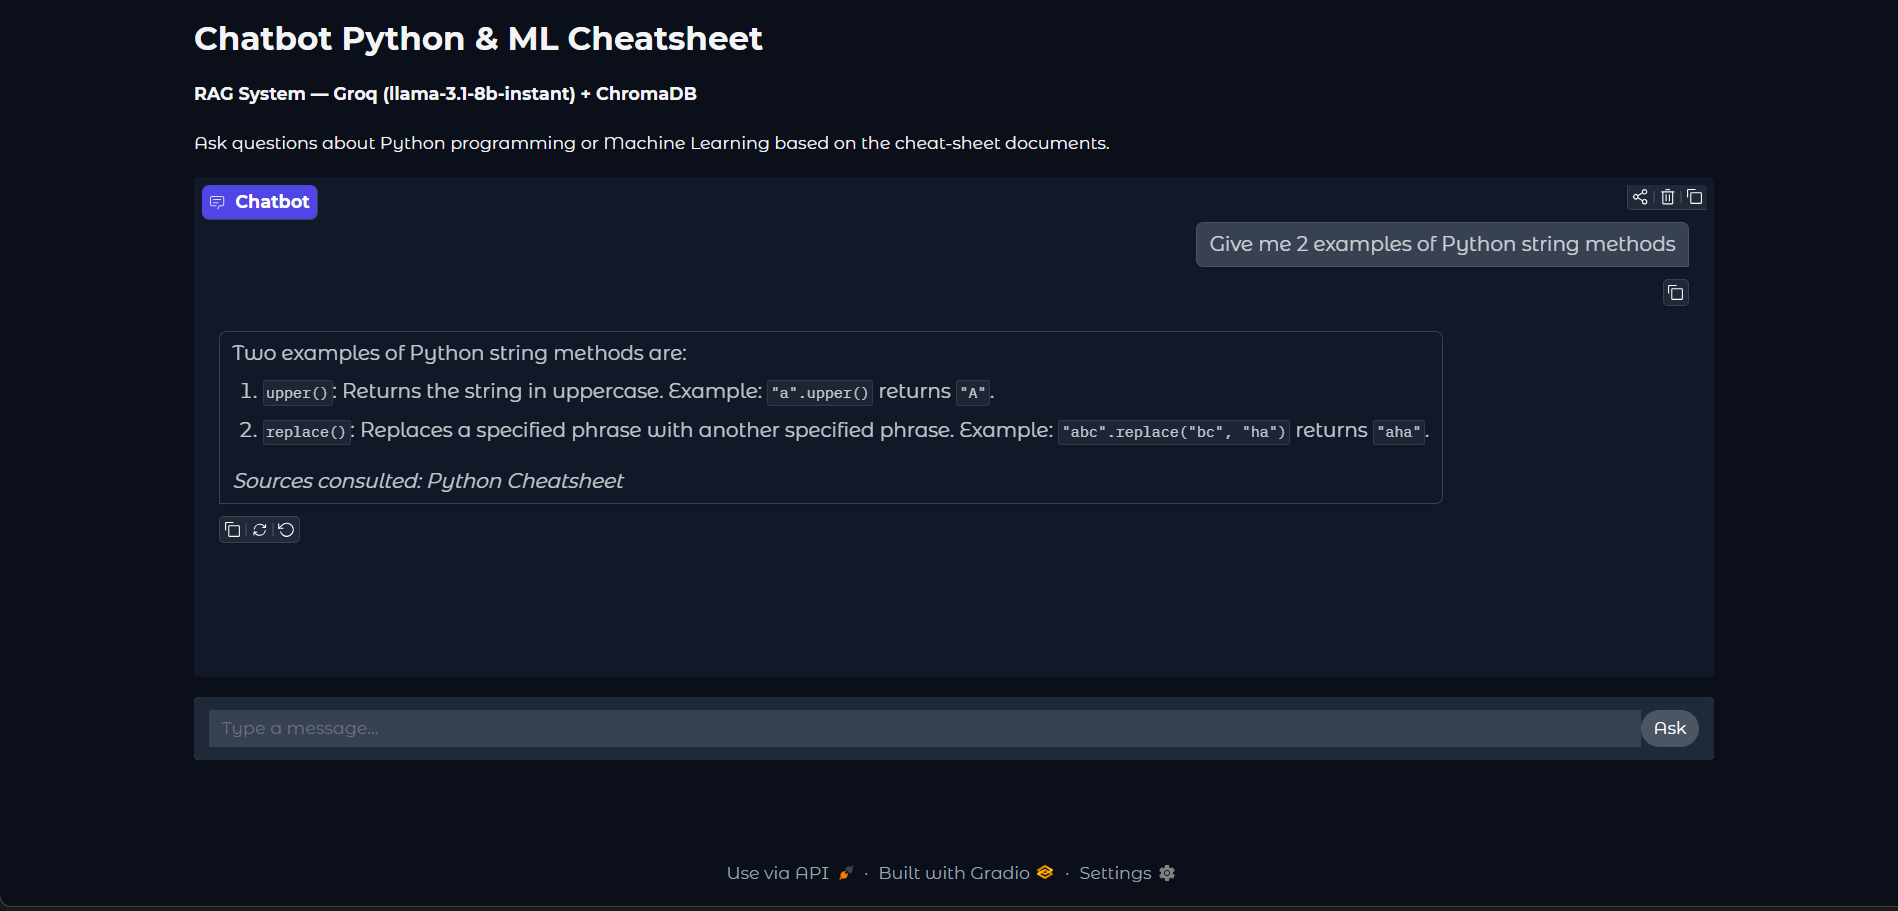

---

**3. Pregunta sobre diccionarios en Python**

Respuesta precisa con dos métodos de creación: literal `{}` y función `dict()`, ambos documentados en el cheatsheet.

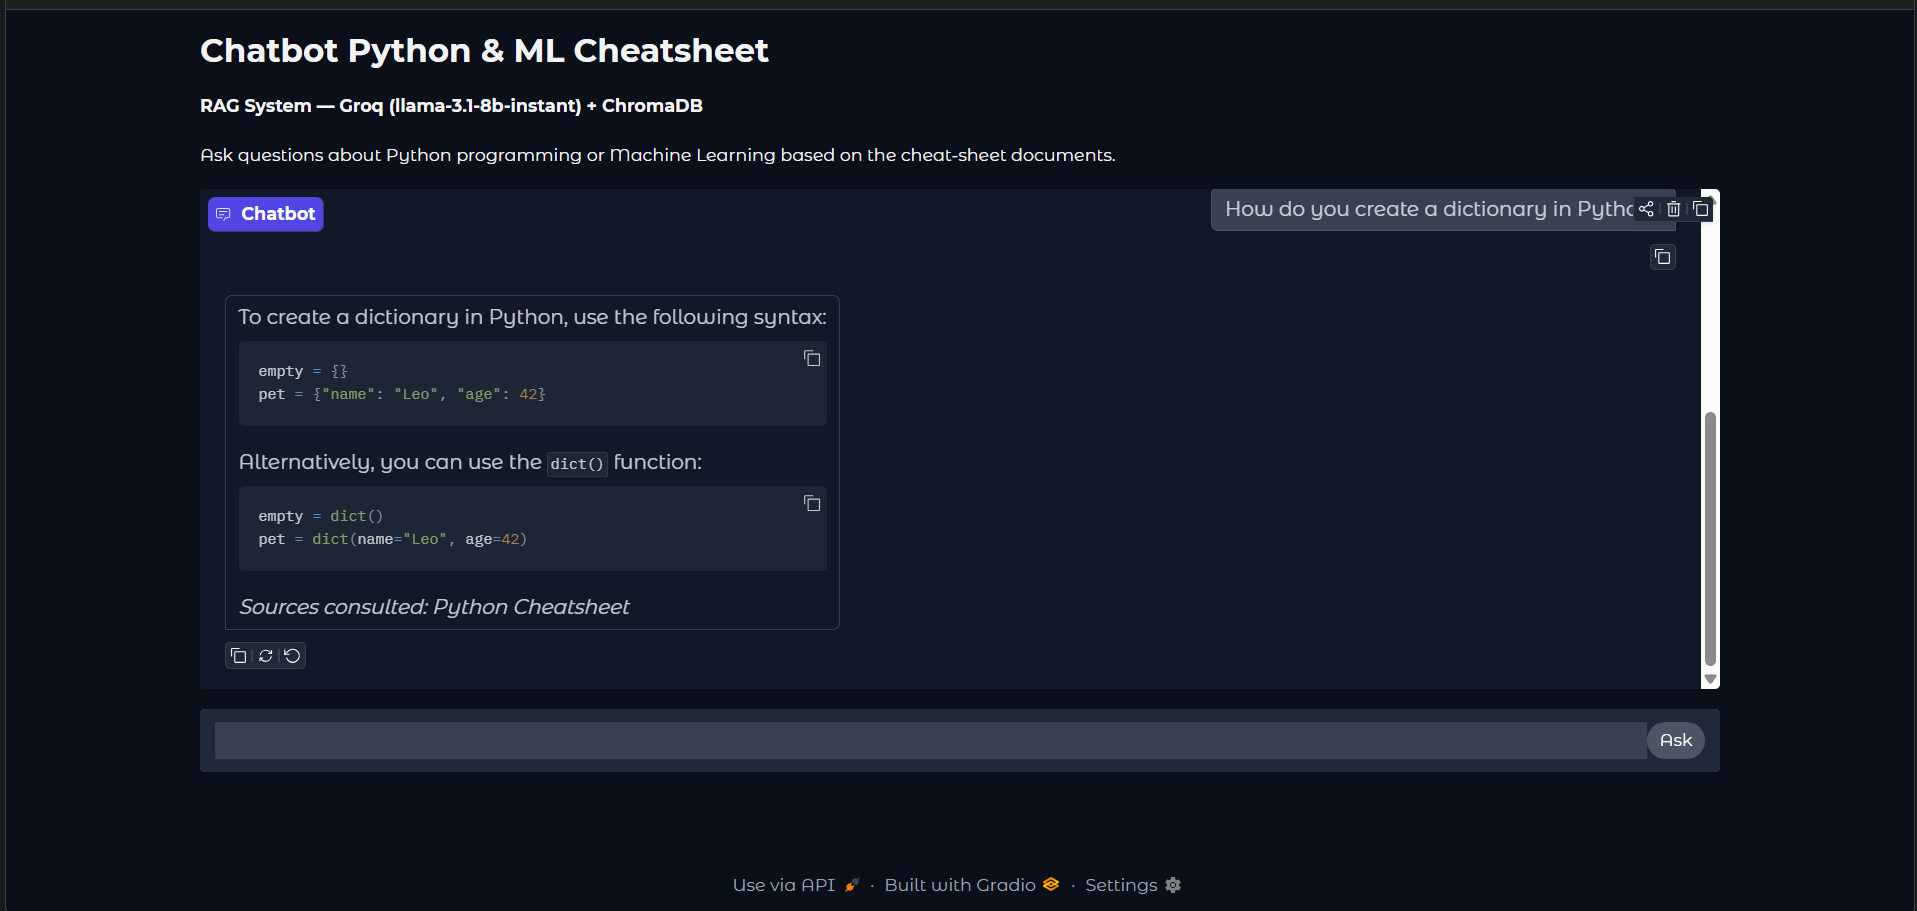

---

**4. Pregunta sobre lectura de archivos en Python**

El chatbot devuelve ambas variantes del cheatsheet: lectura completa con `file.read()` y lectura línea por línea con un bucle `for`.

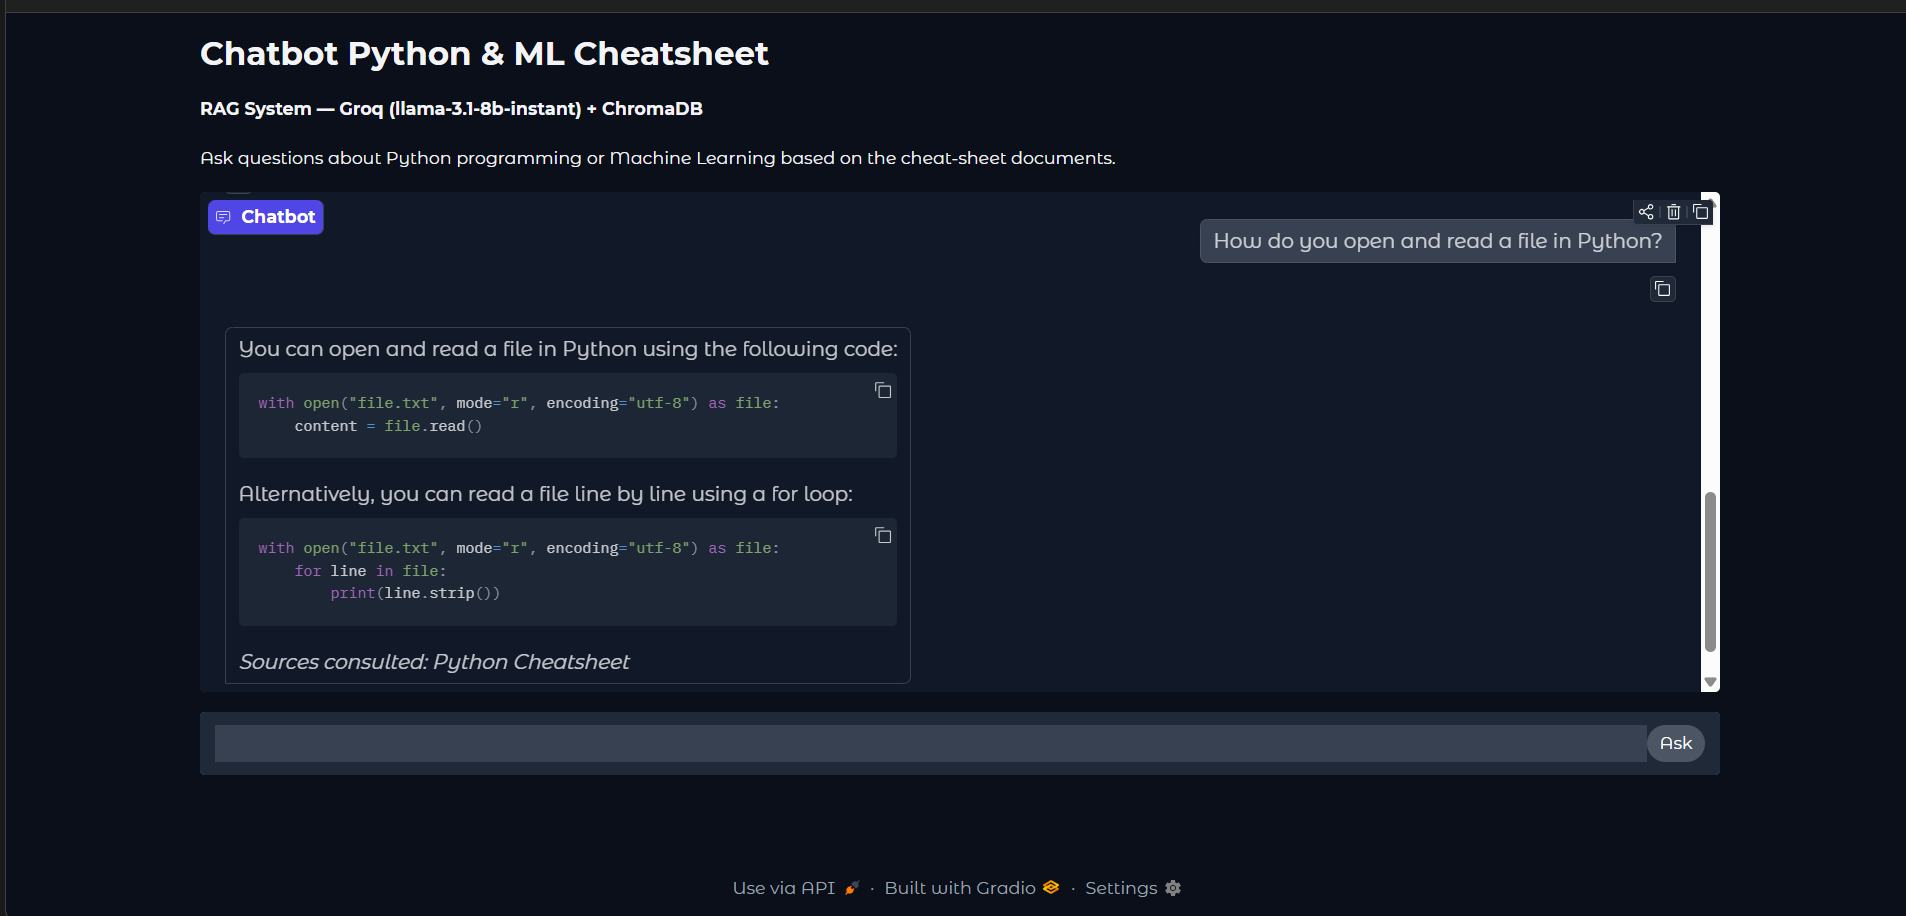

---

**5. Preguntas sobre ML: Logistic Regression y Linear Regression**

Respuestas extraídas correctamente de las tablas del ML Cheatsheet, demostrando que la estrategia de extracción con pdfplumber funciona para información tabular.

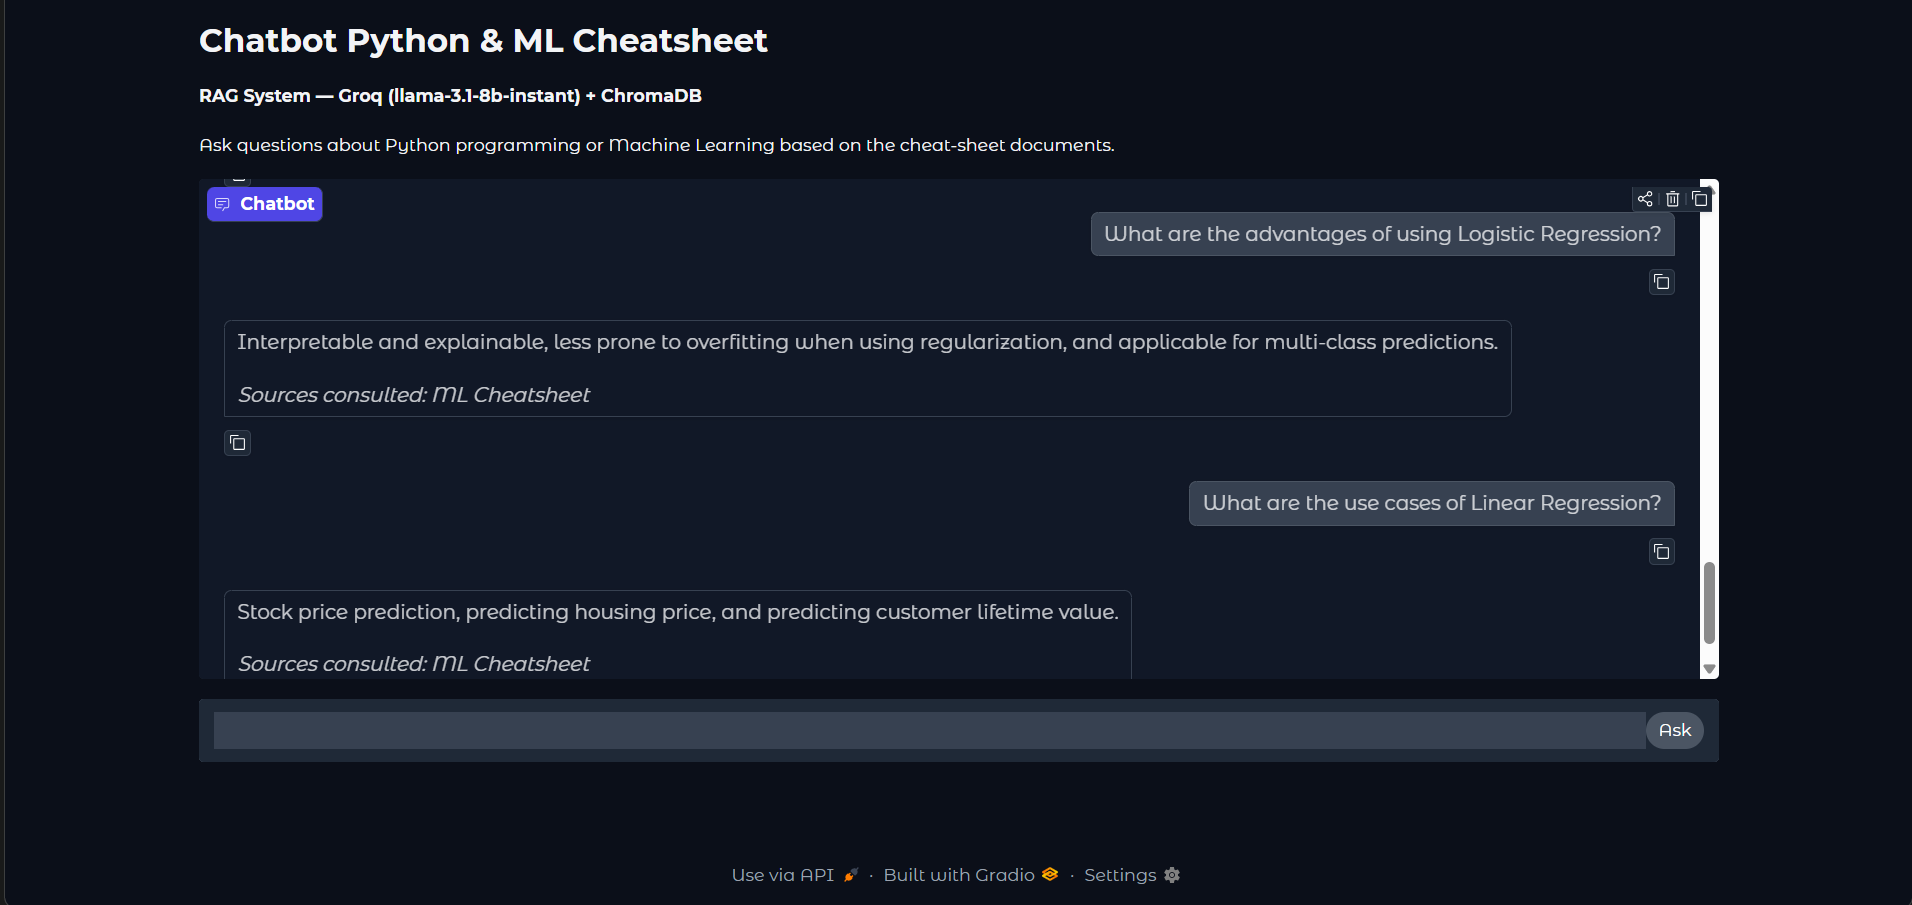

---

**6. Casos límite — preguntas fuera del contexto**

Al preguntar "Who invented Python?" y "What is the capital of France?", el sistema responde "I could not find this information in the provided documents", confirmando que el prompt restrictivo evita el uso de conocimiento externo.

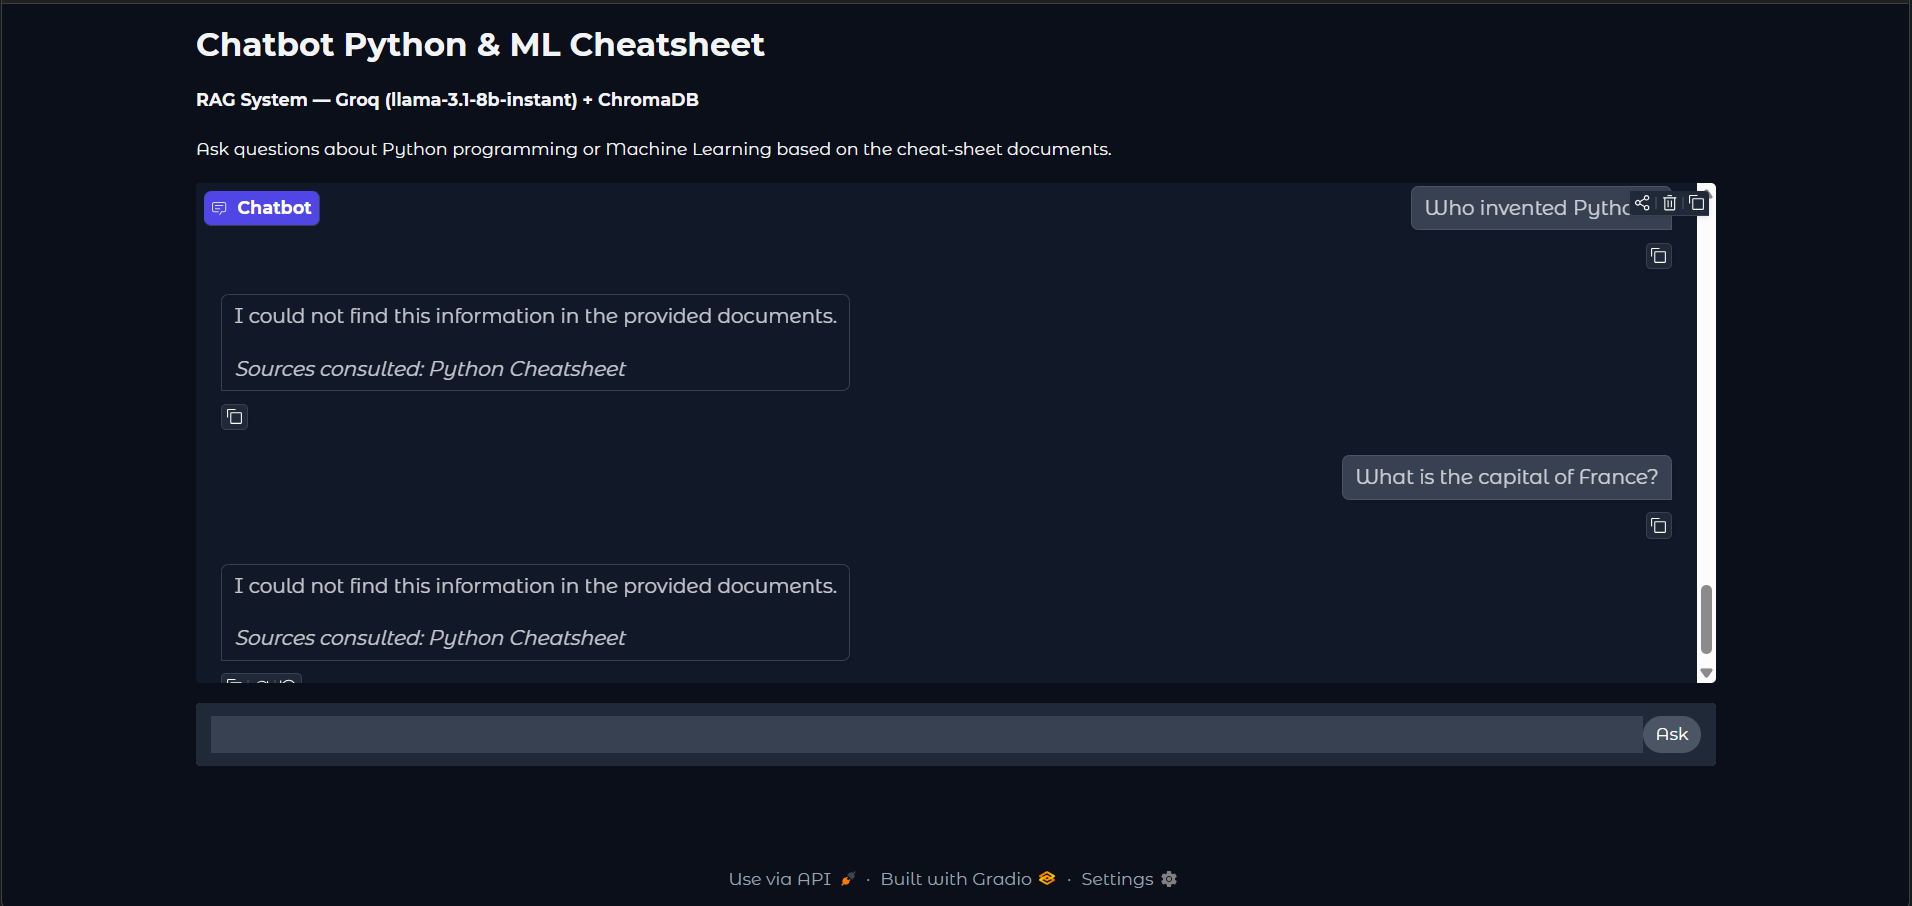



In [ ]:
import base64
from IPython.display import Markdown, display

# filename → (title, description)
screenshots = [
    ("chatbot1.png", "Interfaz inicial — ejemplos precargados",
     "Vista inicial del chatbot con los 4 ejemplos precargados disponibles para el usuario."),
    ("chatbot2.png", "Pregunta sobre métodos de cadena en Python",
     "El sistema recupera el chunk correcto del Python Cheatsheet y devuelve dos ejemplos "
     "con su sintaxis: `upper()` y `replace()`, tomados directamente del documento fuente."),
    ("chatbot3.png", "Pregunta sobre diccionarios en Python",
     "Respuesta precisa con dos métodos de creación: literal `{}` y función `dict()`, "
     "ambos documentados en el cheatsheet."),
    ("chatbot4.png", "Pregunta sobre lectura de archivos en Python",
     "El chatbot devuelve ambas variantes del cheatsheet: lectura completa con `file.read()` "
     "y lectura línea por línea con un bucle `for`."),
    ("chatbot5.png", "Preguntas sobre ML: Logistic Regression y Linear Regression",
     "Respuestas extraídas correctamente de las tablas del ML Cheatsheet, demostrando que "
     "la estrategia de extracción con pdfplumber funciona para información tabular."),
    ("chatbot6.png", "Casos límite — preguntas fuera del contexto",
     'Al preguntar "Who invented Python?" y "What is the capital of France?", el sistema '
     'responde "I could not find this information in the provided documents", confirmando '
     "que el prompt restrictivo evita el uso de conocimiento externo."),
]

# Build the full markdown string in one loop
md = "### Demostración del chatbot\n\n"
md += "Las siguientes capturas muestran el comportamiento del sistema RAG en distintos escenarios.\n\n"

for i, (filename, title, description) in enumerate(screenshots, 1):
    with open(filename, "rb") as f:
        b64 = base64.b64encode(f.read()).decode("utf-8")
    ext = filename.split(".")[-1]   # handles both .png and .jpg
    md += f"---\n\n**{i}. {title}**\n\n"
    md += f"{description}\n\n"
    md += f'<img src="data:image/{ext};base64,{b64}" width="800"/>\n\n'

display(Markdown(md))

---
## 11: Análisis técnico — Manejo de tablas y alucinaciones

### Retos de la información tabular

1. **Extracción imperfecta**: pdfplumber detecta tablas por separadores de línea, pero las tablas con bordes inconsistentes pueden extraerse de forma fragmentada.

2. **Chunking de tablas**: Al dividir el texto por tamaño, una tabla Markdown puede quedar cortada a la mitad, perdiendo la asociación encabezado-valor.

3. **Embeddings semánticos vs. tabulares**: Los modelos de embeddings (como MiniLM) están optimizados para texto narrativo; las tablas en Markdown tienen semántica distinta que puede afectar la recuperación.

### Estrategias para mitigar alucinaciones

- **Prompt restrictivo**: El template indica al LLM responder SOLO desde el contexto recuperado.

- **Baja temperatura** (0.2): Reduce respuestas creativas o inventadas.

- **Citar fuentes**: El chatbot muestra qué documento fue consultado en cada respuesta.

- **k=5 chunks**: Se recuperan más fragmentos para aumentar la probabilidad de incluir la respuesta correcta.



---
## 12: Conclusiones

* La estrategia híbrida de extracción fue determinante para la calidad
  de las respuestas. Usar PyMuPDF con ordenamiento por columnas para el Python Cheatsheet
  y pdfplumber exclusivamente para las tablas reales del ML Cheatsheet produjo chunks
  limpios y semánticamente coherentes. Aplicar pdfplumber en ambos PDFs generaba grillas
  de layout visual de hasta 96 columnas con contenido mezclado e ilegible, identificada
  como la principal fuente de alucinaciones durante el desarrollo. Sin embargo, esta
  solución no es robusta para un entorno de producción: la lógica de extracción está
  hardcodeada por tipo de PDF, lo que significa que agregar un nuevo documento requeriría
  modificar el código manualmente.

* El chatbot respondió correctamente las 6 preguntas requeridas.
  Para las preguntas a–e, el sistema recuperó los chunks correctos y generó respuestas
  precisas tanto para texto plano (Python Cheatsheet) como para información tabular
  (ML Cheatsheet). La pregunta f, propuesta por el equipo, consultó un tema no cubierto
  en los cheatsheets; el chatbot respondió correctamente con "I could not find this
  information", demostrando que el sistema respeta la limitación de usar únicamente
  los PDFs proporcionados sin recurrir a conocimiento externo.

* Las estrategias anti-alucinación fueron efectivas en todos los casos.
  El prompt restrictivo y la baja temperatura (0.2) lograron que el modelo nunca fabricara una respuesta: cuando la información no estaba
  en el contexto recuperado, el sistema lo indicó explícitamente en lugar de inventar.
  Este es el comportamiento esperado y deseable en un sistema RAG de producción.

* El sistema RAG demostró ser más preciso que un LLM sin contexto para
  preguntas específicas sobre los documentos. Sin RAG, el modelo generaría respuestas
  genéricas basadas en su entrenamiento general, sin garantía de correspondencia con el
  contenido exacto de los cheatsheets. La combinación de ChromaDB con embeddings locales
  (all-MiniLM-L6-v2) permitió recuperar los fragmentos relevantes con alta precisión
  usando similitud coseno, validando la utilidad del enfoque RAG para bases de conocimiento
  específicas y privadas.

* Los chatbots comerciales como ChatGPT, Gemini y Claude abordan la
  extracción de PDFs de forma distinta: utilizan visión nativa para renderizar cada página
  como imagen y procesarla con modelos multimodales, entendiendo texto, tablas y gráficas
  en un solo paso sin pipeline explícito. Nuestra implementación, en cambio, ofrece control
  total sobre cada etapa: extracción, chunking, embeddings y recuperación, lo cual es
  valioso cuando se requiere transparencia, privacidad de datos o personalización del
  pipeline, a costa de mayor complejidad de implementación.

  > Referencias:
  > - Google AI. (2026). *Document understanding - Gemini API*. https://ai.google.dev/gemini-api/docs/document-processing



---
# **Fin de la actividad Chatbot: LLM + RAG**

In [ ]:
import base64

# Map filename to a short label for the markdown
screenshots = [
    ("chatbot1.png", "Interfaz inicial — ejemplos precargados"),
    ("chatbot2.png", "Pregunta sugeridad sobre Python: string methods"),
    ("chatbot3.png", "Pregunta libre sobre Python: crear diccionario"),
    ("chatbot4.png", "Pregunta librre sobre Python: leer archivo"),
    ("chatbot5.png", "Pregunta  libre sobre ML: Logistic Regression y Linear Regression"),
    ("chatbot6.png", "Caso límite — preguntas fuera del contexto"),
]

b64_images = {}
for filename, label in screenshots:
    with open(filename, "rb") as f:
        b64_images[filename] = base64.b64encode(f.read()).decode("utf-8")
    print(f"Done: {filename}")

print("\nAll images encoded. Copy each b64_images['filename'] into the markdown")

Done: chatbot1.png
Done: chatbot2.png
Done: chatbot3.png
Done: chatbot4.png
Done: chatbot5.png
Done: chatbot6.png

All images encoded. Copy each b64_images['filename'] into the markdown below.
